In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv(
    "../data/processed/customer_feedback_processed.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 9)


,label,title,content,review_text,lowercase_text,cleaned_text,tokens,filtered_tokens,lemmatized_tokens
0,0,Defected Product,I purchased this product because my cat prefer...,Defected Product. I purchased this product bec...,defected product. i purchased this product bec...,defected product i purchased this product beca...,"['defected', 'product', 'i', 'purchased', 'thi...","['defected', 'product', 'purchased', 'product'...","['defected', 'product', 'purchased', 'product'..."
1,0,problem with product,The product I received came in time but was da...,problem with product. The product I received c...,problem with product. the product i received c...,problem with product the product i received ca...,"['problem', 'with', 'product', 'the', 'product...","['problem', 'product', 'product', 'received', ...","['problem', 'product', 'product', 'received', ..."
2,0,can't handle power losses - active ports fry o...,I have just fried my second of this model. Whe...,can't handle power losses - active ports fry o...,can't handle power losses - active ports fry o...,cant handle power losses active ports fry on p...,"['cant', 'handle', 'power', 'losses', 'active'...","['cant', 'handle', 'power', 'losses', 'active'...","['cant', 'handle', 'power', 'loss', 'active', ..."
3,0,"Looks great, poor performance",I bought this high end kettle thinking I would...,"Looks great, poor performance. I bought this h...","looks great, poor performance. i bought this h...",looks great poor performance i bought this hig...,"['looks', 'great', 'poor', 'performance', 'i',...","['looks', 'great', 'poor', 'performance', 'bou...","['look', 'great', 'poor', 'performance', 'boug..."
4,1,perfect for loose teas,Looked a long time for this. Careful- it holds...,perfect for loose teas. Looked a long time for...,perfect for loose teas. looked a long time for...,perfect for loose teas looked a long time for ...,"['perfect', 'for', 'loose', 'teas', 'looked', ...","['perfect', 'loose', 'teas', 'looked', 'long',...","['perfect', 'loose', 'tea', 'looked', 'long', ..."


In [3]:
X = df['cleaned_text']

y = df['label']

print("Input data shape:", X.shape)
print("Output data shape:", y.shape)

print("\nSample input:")
print(X.iloc[0])

print("\nSample output:")
print(y.iloc[0])

Input data shape: (10000,)
Output data shape: (10000,)

Sample input:
defected product i purchased this product because my cat prefers to drink from running water source i bought it to replace a fountain we had for three years this one did not even last a few months at first i was pleased with the noise level nice and quiet but within a month the water stopped shooting out of the mouth i believe the motor is defected the only way it works if you remove the fish and with cover not sure if this is an isolated case but i would be wary of purchasing the cats rule fountains too bad because they are cute

Sample output:
0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [5]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (8000, 10000)
Testing TF-IDF shape: (2000, 10000)


In [6]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [7]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")

print("\nActual sentiments:")
print(y_test.head(10).tolist())

print("\nPredicted sentiments:")
print(y_pred[:10].tolist())

Predictions completed!

Actual sentiments:
[0, 1, 0, 1, 0, 0, 0, 1, 1, 1]

Predicted sentiments:
[0, 0, 0, 1, 0, 1, 0, 1, 1, 1]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Negative', 'Positive']
    )
)

Model Accuracy: 88.85 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.89      0.89      1001
    Positive       0.89      0.89      0.89       999

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000



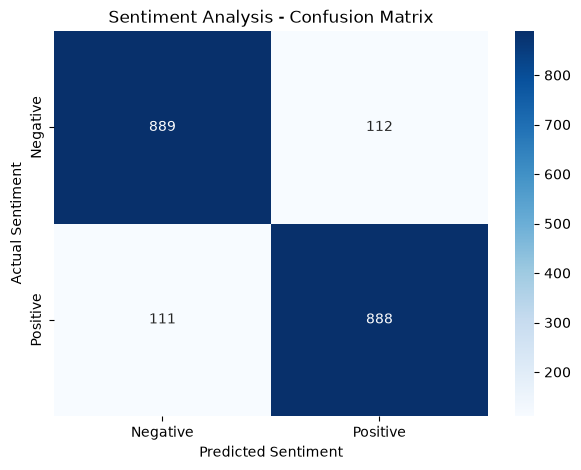

In [9]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title("Sentiment Analysis - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()


## Model Evaluation – Logistic Regression

### Model Performance

The Logistic Regression model was trained using TF-IDF
vectorization and evaluated on 2,000 customer reviews.

### Confusion Matrix Results

- True Negative: 889
- True Positive: 888
- False Positive: 112
- False Negative: 111

### Key Findings

- Model accuracy is approximately 88.85%.
- The model performs consistently across positive and negative reviews.
- The model correctly classified 1,777 out of 2,000 reviews.
- A total of 223 reviews were incorrectly classified.

### Conclusion

The TF-IDF and Logistic Regression approach provides
a strong baseline for customer sentiment classification.

We will use this baseline to compare performance with
a transformer-based BERT model.


In [10]:
new_reviews = [
    "This product is absolutely amazing. I love it!",
    "Terrible product. Very disappointed with the quality.",
    "The delivery was fast and the product works perfectly.",
    "Worst purchase ever. I regret buying this.",
    "The product is okay but nothing special."
]

# Transform new reviews using our trained TF-IDF vectorizer
new_reviews_tfidf = tfidf.transform(new_reviews)

# Predict sentiment
predictions = model.predict(new_reviews_tfidf)

# Display results
for review, prediction in zip(new_reviews, predictions):

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 80)

Review: This product is absolutely amazing. I love it!
Predicted Sentiment: Positive
--------------------------------------------------------------------------------
Review: Terrible product. Very disappointed with the quality.
Predicted Sentiment: Negative
--------------------------------------------------------------------------------
Review: The delivery was fast and the product works perfectly.
Predicted Sentiment: Positive
--------------------------------------------------------------------------------
Review: Worst purchase ever. I regret buying this.
Predicted Sentiment: Negative
--------------------------------------------------------------------------------
Review: The product is okay but nothing special.
Predicted Sentiment: Negative
--------------------------------------------------------------------------------


In [11]:
probabilities = model.predict_proba(new_reviews_tfidf)

for review, prediction, probability in zip(
    new_reviews, predictions, probabilities
):

    sentiment = "Positive" if prediction == 1 else "Negative"

    confidence = max(probability) * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:", round(confidence, 2), "%")
    print("-" * 80)

Review: This product is absolutely amazing. I love it!
Predicted Sentiment: Positive
Confidence: 84.45 %
--------------------------------------------------------------------------------
Review: Terrible product. Very disappointed with the quality.
Predicted Sentiment: Negative
Confidence: 94.15 %
--------------------------------------------------------------------------------
Review: The delivery was fast and the product works perfectly.
Predicted Sentiment: Positive
Confidence: 76.01 %
--------------------------------------------------------------------------------
Review: Worst purchase ever. I regret buying this.
Predicted Sentiment: Negative
Confidence: 79.53 %
--------------------------------------------------------------------------------
Review: The product is okay but nothing special.
Predicted Sentiment: Negative
Confidence: 84.16 %
--------------------------------------------------------------------------------


### Prediction Confidence Analysis

The trained Logistic Regression model was tested using
five manually created customer reviews.

The model generated sentiment predictions along with
probability estimates.

Observations:

- Strong positive reviews were classified correctly.
- Strong negative reviews were classified correctly.
- The model assigned different confidence levels
  depending on the review content.
- Neutral or ambiguous reviews were forced into
  either positive or negative categories.

Conclusion:

The model successfully demonstrates binary sentiment
classification with probability-based predictions.

A three-class classification system could improve
the handling of neutral customer feedback.

In [12]:
import os
import joblib

# Create model directory
model_dir = "../models/logistic_regression"
os.makedirs(model_dir, exist_ok=True)

# Save trained model
joblib.dump(
    model,
    os.path.join(model_dir, "sentiment_model.pkl")
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    os.path.join(model_dir, "tfidf_vectorizer.pkl")
)

print("Logistic Regression model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Logistic Regression model saved successfully!
TF-IDF vectorizer saved successfully!


In [13]:
print(os.listdir(model_dir))

['sentiment_model.pkl', 'tfidf_vectorizer.pkl']
